# Homoscedasticity vs. Heteroscedasticity

We study

$$
Y_i=\beta_0+\beta_1X_i+\varepsilon_i.
$$

Homoscedasticity:

$$
\operatorname{Var}(\varepsilon_i\mid X_i=x)=\sigma^2.
$$

Heteroscedasticity:

$$
\operatorname{Var}(\varepsilon_i\mid X_i=x)=\sigma^2(x).
$$

The examples below have the same linear mean structure but different noise variance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(10)
n = 120
x = np.linspace(0, 10, n)
mu = 2 + 1.5*x

## 1. Homoscedastic data

$$
Y_i=2+1.5X_i+\varepsilon_i,
\qquad
\varepsilon_i\sim N(0,1.5^2).
$$

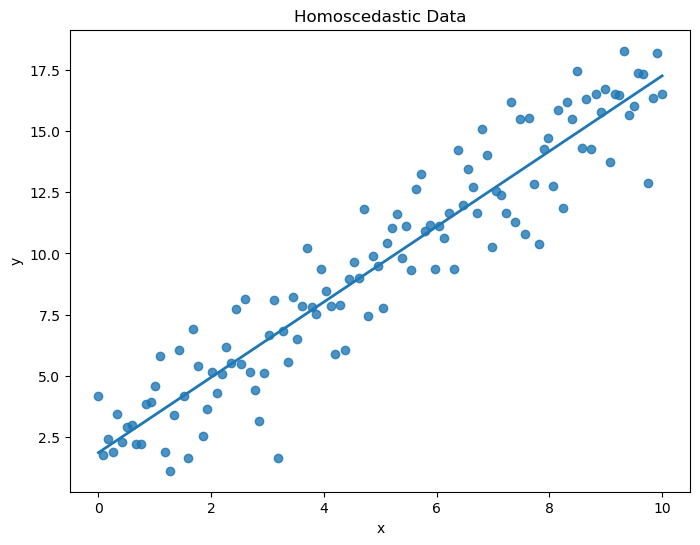

In [5]:
sigma = 1.5
y_homo = mu + rng.normal(0, sigma, n)

m_homo = LinearRegression().fit(x.reshape(-1,1), y_homo)
yhat_homo = m_homo.predict(x.reshape(-1,1))

plt.figure(figsize=(8,6))
plt.scatter(x, y_homo, alpha=0.8)
plt.plot(x, yhat_homo, linewidth=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Homoscedastic Data")
plt.savefig('homosced.png',dpi=500)

The vertical spread around the fitted line is roughly constant:

$$
\operatorname{Var}(Y\mid X=x)=\sigma^2.
$$

## 2. Heteroscedastic data

Now keep the same conditional mean,

$$
E[Y\mid X=x]=2+1.5x,
$$

but let the noise standard deviation grow with \(x\):

$$
\sigma(x)=0.4+0.35x.
$$

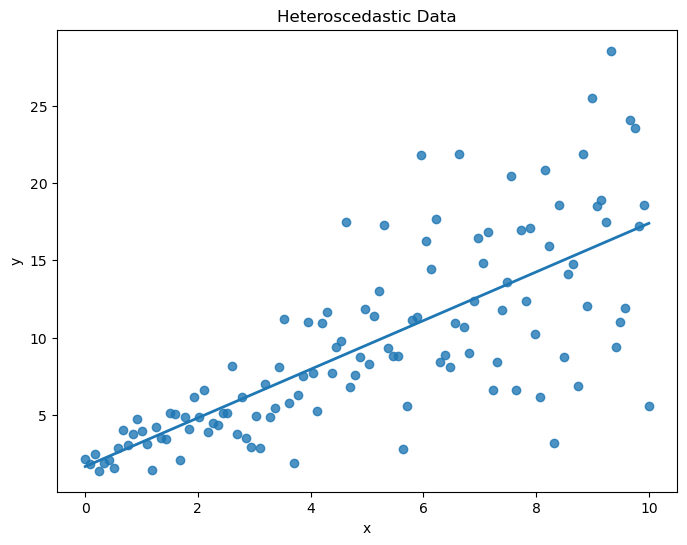

In [4]:
sigma_x = 0.4 + 0.65*x
y_hetero = mu + rng.normal(0, sigma_x)

m_hetero = LinearRegression().fit(x.reshape(-1,1), y_hetero)
yhat_hetero = m_hetero.predict(x.reshape(-1,1))

plt.figure(figsize=(8,6))
plt.scatter(x, y_hetero, alpha=0.8)
plt.plot(x, yhat_hetero, linewidth=2)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Heteroscedastic Data")
plt.savefig('heterosced.png',dpi=500)

The regression mean is still linear. What changes is the spread:

$$
x\uparrow
\quad\Longrightarrow\quad
\operatorname{Var}(Y\mid X=x)\uparrow.
$$

This creates the characteristic fan shape.

## 3. Side-by-side comparison

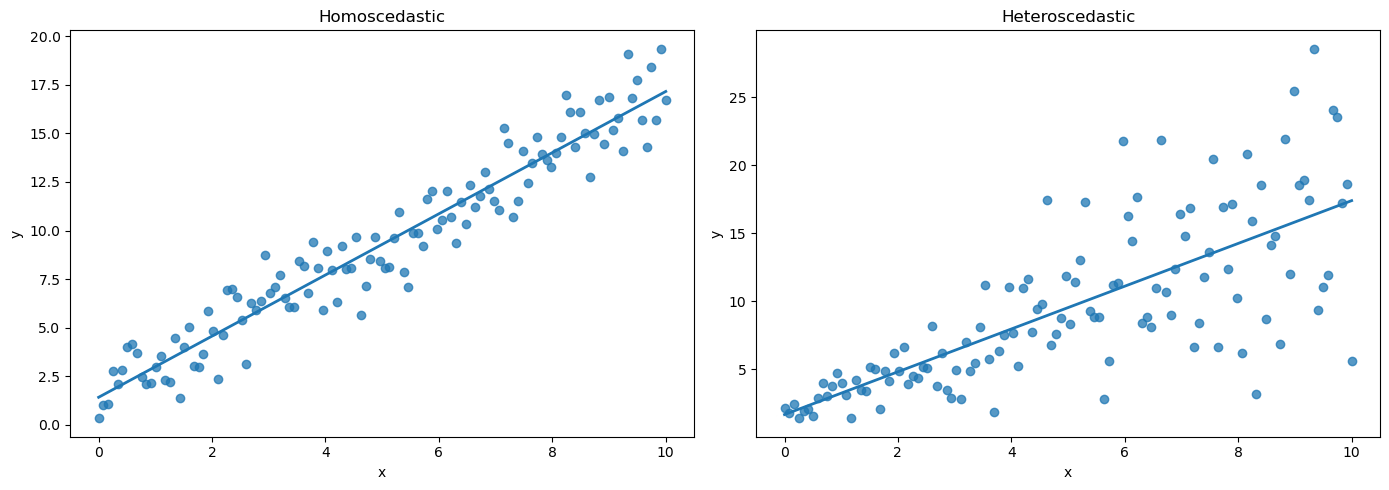

In [6]:
fig, axes = plt.subplots(1,2,figsize=(14,5),sharex=True)

axes[0].scatter(x,y_homo,alpha=0.75)
axes[0].plot(x,yhat_homo,linewidth=2)
axes[0].set_title("Homoscedastic")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

axes[1].scatter(x,y_hetero,alpha=0.75)
axes[1].plot(x,yhat_hetero,linewidth=2)
axes[1].set_title("Heteroscedastic")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")

plt.tight_layout()
plt.show()

## 4. Residual plots

For observation \(i\),

$$
e_i=y_i-\hat y_i.
$$

Plotting residuals against fitted values makes the difference even clearer.

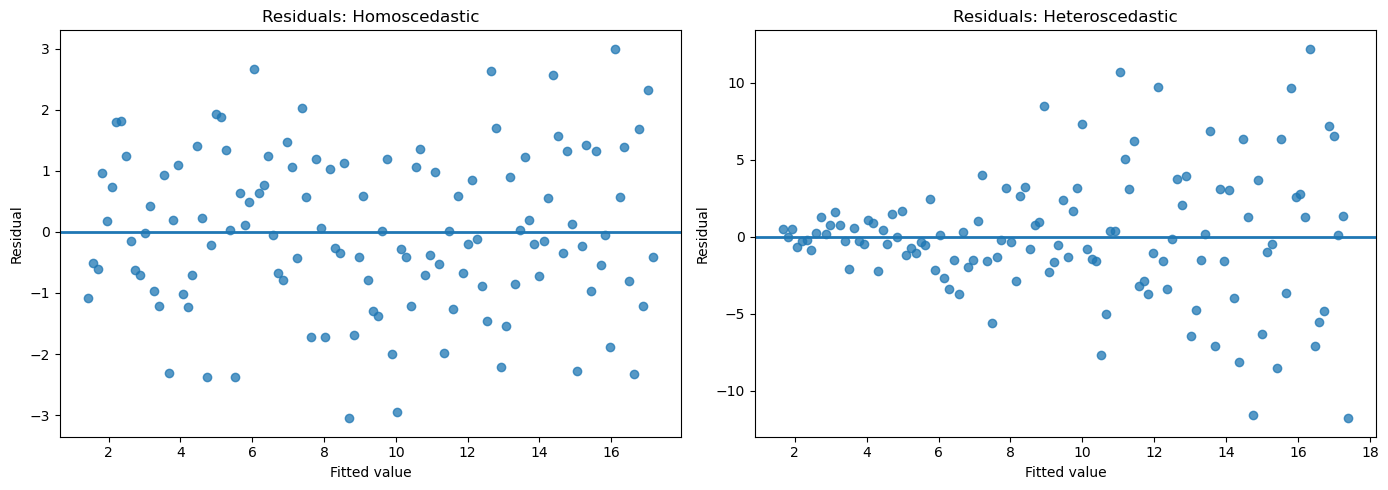

In [7]:
res_homo = y_homo - yhat_homo
res_hetero = y_hetero - yhat_hetero

fig, axes = plt.subplots(1,2,figsize=(14,5))

axes[0].scatter(yhat_homo,res_homo,alpha=0.75)
axes[0].axhline(0,linewidth=2)
axes[0].set_title("Residuals: Homoscedastic")
axes[0].set_xlabel("Fitted value")
axes[0].set_ylabel("Residual")

axes[1].scatter(yhat_hetero,res_hetero,alpha=0.75)
axes[1].axhline(0,linewidth=2)
axes[1].set_title("Residuals: Heteroscedastic")
axes[1].set_xlabel("Fitted value")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

### Take-home message

$$
\boxed{\text{Homoscedasticity}=\text{constant residual variance}}
$$

$$
\boxed{\text{Heteroscedasticity}=\text{residual variance changes with }X}
$$

This is about the **noise around the regression line**, not about the scale of the predictor.